&nbsp;

&nbsp;

## Survey: ENEMAL - CRE pairs

&nbsp;

### BackGround

- `ENST00000701343.2` (eRNA of the NE__AT1-MA__LAT1-Locus (eNEMAL)) が、hypoxia で発現上昇することを報告している論文を発見したことと、今回の up5p transcript list に含まれていることを確認した
- [eNEMAL, an enhancer RNA transcribed from a distal MALAT1 enhancer, promotes NEAT1 long isoform expression](https://doi.org/10.1371/journal.pone.0251515) 

&nbsp;

In [1]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image
from pygenometracks.readGtf import ReadGtf

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261019


&nbsp;

&nbsp;

## ENEMAL - CRE pairs

- 今回の解析で、具体的にどのような transcript - CRE pair が取得できたか確認する

In [3]:
ENEMAL_cre_pair = pl.read_parquet(
    "../../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
).filter(
    (pl.col("gene_symbol") == "ENEMAL")
    & (pl.col("HGNC_ID") == "HGNC:56747")
)

print(f"ENEMAL cre all pair: {ENEMAL_cre_pair.select(['transcript_id', 'cre_id']).n_unique()}")
display(ENEMAL_cre_pair)

ENEMAL cre all pair: 5


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000701343.2""",117,36,253,81,74,15,162,59,"""ENEMAL""","""HGNC:56747""","""lncRNA""","""ENSG00000289883.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A39AA9""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_73647""","""chr11""",65476719,"""65477145""","""cp1@ENEMAL""","[""NR_186313.1""]","""-342""",-427,"[{""EH38E1545172"",""dELS""}, {""EH38E2964387"",""dELS""}, {""EH38E2964388"",""dELS""}]","[{""ETV6"",1990,[{""SRX11661386"",1990}, {""SRX11661388"",1839}, … {""SRX11661389"",1621}]}, {""CTCF"",1595,[{""SRX12008351"",1595}, {""SRX12008350"",1304}, … {""SRX12008355"",637}]}, … {""SNAI2"",528,[{""SRX476922"",528}]}]","[{""HS_00156135"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156136"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00156140"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.873684,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000701343.2""",117,36,253,81,74,15,162,59,"""ENEMAL""","""HGNC:56747""","""lncRNA""","""ENSG00000289883.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A39AA9""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_73648""","""chr11""",65477044,"""65477442""","""cp3@ENEMAL""","[""NR_186313.1""]","""-45""",-130,"[{""EH38E2964387"",""dELS""}, {""EH38E2964388"",""dELS""}, {""EH38E2964389"",""dELS""}]","[{""SUPT5H"",2625,[{""SRX2314263"",2625}, {""SRX2314264"",2130}, … {""SRX9237234"",582}]}, {""ZNF143"",2557,[{""SRX1510971"",2557}, {""SRX1510969"",2497}]}, … {""TFAP2B"",503,[{""SRX16499958"",503}]}]","[{""HS_00156135"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156136"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00156140"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr11:65244638..65244644,-;hg_120583.1"",""hg_120583.1""}, {""hg19::chr11:65244691..65244707,-;hg_120584.1"",""hg_120584.1""}, {""hg19::chr11:65244911..65244971,-;hg_120585.1"",""hg_120585.1""}]","[{[""chr11:65477165-65477832""]}]",-0.817112,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000701343.2""",117,36,253,81,74,15,162,59,"""ENEMAL""","""HGNC:56747""","""lncRNA""","""ENSG00000289883.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A39AA9""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_73649""","""chr11""",65477279,"""65477945""","""cp2@ENEMAL""","[""ENST00000701343.2"", ""NR_186313.1""]","""0""",0,"[{""EH38E2964388"",""dELS""}, {""EH38E2964389"",""dELS""}, {""EH38E2964390"",""dELS""}]","[{""MITF"",3960,[{""SRX6878446"",3960}, {""SRX6878445"",3848}, … {""SRX6878431"",506}]}, {""ZNF143"",3721,[{""SRX1510972"",3721}, {""SRX1510970"",3536}, … {""SRX14835721"",514}]}, … {""TFAP2B"",503,[{""SRX16499958"",503}]}]","[{""HS_00156135"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156136"",""Fetal Intestine Smal

&nbsp;

&nbsp;

## 2. ENCODE-rE2G result

- 複数ある transcript - CRE pair の中から、ENCODE-rE2G の結果を活用し、活性化していると思われるCRE とそのペアを選抜する

In [4]:
enemal_encode_re2g_result = pl.read_parquet(
    "../../../out/ENCODE_rE2G/parquet_file/encode_re2g_hs_join_v261003.parquet"
).filter(
    pl.col("isSelfPromoter") == False
).filter(
    # ENEMAL の CRE のみを対象にする
    pl.col("cre_id").is_in(
        ENEMAL_cre_pair.get_column("cre_id").unique().implode()
    )
)

enemal_e2g_join_filter_unique_count = enemal_encode_re2g_result.group_by(
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "target_cre_id",
    "target_cre_name",
    "target_fantabio_cre_class"
).agg(
    # Keep dataset order so this list lines up with the score and overlap lists
    pl.col("re2g_dataset").unique(maintain_order=True).alias("re2g_dataset"),
    pl.col("re2g_dataset").n_unique().alias("re2g_dataset_count"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").alias("enhancer_cre_overlap_frac_of_fantabio_cre"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").min().alias("enhancer_cre_overlap_frac_of_fantabio_cre_min"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").max().alias("enhancer_cre_overlap_frac_of_fantabio_cre_max"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").mean().alias("enhancer_cre_overlap_frac_of_fantabio_cre_mean"), # 該当するデータセットで同定された enhancer と fantabio の CRE の重複率の平均値

    pl.col("ENCODE-rE2G.Score").alias("ENCODE-rE2G.Score"),
    pl.col("ENCODE-rE2G.Score").min().alias("ENCODE-rE2G.Score_min"),
    pl.col("ENCODE-rE2G.Score").max().alias("ENCODE-rE2G.Score_max"),
    pl.col("ENCODE-rE2G.Score").mean().alias("ENCODE-rE2G.Score_mean"), # 該当するデータセットで同定された enhancer と target promoter の相互作用のスコアの平均値

    # pl.col("ENCODE-rE2G.Score").quantile(0.25).alias("ENCODE-rE2G.Score_q1"),
    # pl.col("ENCODE-rE2G.Score").median().alias("ENCODE-rE2G.Score_median"),
    # pl.col("ENCODE-rE2G.Score").quantile(0.75).alias("ENCODE-rE2G.Score_q3"),
    # pl.col("ENCODE-rE2G.Score").std().alias("ENCODE-rE2G.Score_std"),
).sort(
    by=["re2g_dataset_count"],
    descending=True
)

pl.Config.set_tbl_rows(10)
print(f"ENCODE-rE2G enhancer - target region interaction unique pair count (fanta.bio cre level): {enemal_e2g_join_filter_unique_count.select(['cre_id', 'target_cre_id']).n_unique()}")
display(enemal_e2g_join_filter_unique_count)

ENCODE-rE2G enhancer - target region interaction unique pair count (fanta.bio cre level): 36


cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_470991""","""cp8@TALAM1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.324795, 0.287877, … 0.626757]",0.195157,0.626757,0.400493
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73694""","""cp7@MALAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.605596, 0.560305, … 0.775636]",0.515692,0.935818,0.682022
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73545""","""cp2@NEAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.293994, 0.235102, … 0.546226]",0.235102,0.674145,0.492937
"""FCHS_73648""","""cp3@ENEMAL""","""ELA""","""FCHS_470991""","""cp8@TALAM1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[0.972431, 1.0, … 1.0]",0.972431,1.0,0.997879,"[0.324795, 0.287877, … 0.626757]",0.195157,0.626757,0.396011
"""FCHS_73648""","""cp3@ENEMAL""","""ELA""","""FCHS_73545""","""cp2@NEAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[0.972431, 1.0, … 1.0]",0.972431,1.0,0.997879,"[0.293994, 0.235102, … 0.546226]",0.235102,0.674145,0.495923
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_73648""","""cp3@ENEMAL""","""ELA""","""FCHS_73856""","""cp6@SIPA1""","""PLA""","[""GSE105028_hESC_42C_60min""]",1,[1.0],1.0,1.0,1.0,[0.297571],0.297571,0.297571,0.297571
"""FCHS_73651""","""cp6@ENEMAL""","""ELA""","""FCHS_73694""","""cp7@MALAT1""","""PLA""","[""GSE173536_lymphblastoid_d21_42C_60min""]",1,[0.878906],0.878906,0.878906,0.878906,[0.515692],0.515692,0.515692,0.515692
"""FCHS_73651""","""cp6@ENEMAL""","""ELA""","""FCHS_470991""","""cp8@TALAM1""","""PLA""","[""GSE173536_lymphblastoid_d21_42C_60min""]",1,[0.878906],0.878906,0.878906,0.878906,[0.195157],0.195157,0.195157,0.195157


&nbsp;

&nbsp;

&nbsp;

## 3． Selection of Representative CRE

- 制御されている側の CRE (target_cre_id)から見ると、複数の ENEMAL 由来の CREがある (MALAT1 と紐づく FCHS_73694 を調べると、FCHS_73649, )
- これを解消するために、計算した 熱ストレス関連データ由来の encode-re2g dataset の数が多い (より多く支持されていることを意味する) CREを代表的な CRE として選抜する

In [5]:
# For each target_cre_id, keep the row(s) with the highest re2g_dataset_count
enemal_e2g_top_per_target = enemal_e2g_join_filter_unique_count.filter(
    pl.col("re2g_dataset_count")
    == pl.col("re2g_dataset_count").max().over("target_cre_id")
).sort(
    by=["re2g_dataset_count"],
    descending=True
)

pl.Config.set_tbl_rows(100)
print(f"Unique target_cre_id: {enemal_e2g_top_per_target.select('target_cre_id').n_unique()}")
print(f"Rows after filtering: {enemal_e2g_top_per_target.height}")
display(enemal_e2g_top_per_target)

Unique target_cre_id: 8
Rows after filtering: 13


cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_470991""","""cp8@TALAM1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.324795, 0.287877, … 0.626757]",0.195157,0.626757,0.400493
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73694""","""cp7@MALAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.605596, 0.560305, … 0.775636]",0.515692,0.935818,0.682022
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73545""","""cp2@NEAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.293994, 0.235102, … 0.546226]",0.235102,0.674145,0.492937
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73518""","""cp2@FRMD8""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",12,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.948526,"[0.197967, 0.207562, … 0.392341]",0.197967,0.392341,0.316271
"""FCHS_73648""","""cp3@ENEMAL""","""ELA""","""FCHS_73510""","""cp12@SLC25A45""","""PLA""","[""GSE154744_K562_42C_30min"", ""GSE154744_K562_42C_60min"", … ""GSE280307_THP1_42C_120min""]",5,"[1.0, 1.0, … 1.0]",1.0,1.0,1.0,"[0.229779, 0.212437, … 0.239355]",0.204217,0.267245,0.230607
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73510""","""cp12@SLC25A45""","""PLA""","[""GSE154744_K562_42C_30min"", ""GSE154744_K562_42C_60min"", … ""GSE280307_THP1_42C_120min""]",5,"[1.0, 1.0, … 0.931034]",0.931034,1.0,0.972414,"[0.229779, 0.212437, … 0.239355]",0.204217,0.267245,0.230607
"""FCHS_73648""","""cp3@ENEMAL""","""ELA""","""FCHS_73490""","""cp1@TIGD3""","""PLA""","[""GSE105028_hESC_42C_60min"", ""GSE280307_THP1_42C_120min""]",2,"[1.0, 1.0]",1.0,1.0,1.0,"[0.89562, 0.21975]",0.21975,0.89562,0.557685
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73490""","""cp1@TIGD3""","""PLA""","[""GSE105028_hESC_42C_60min"", ""GSE280307_THP1_42C_120min""]",2,"[1.0, 0.931034]",0.931034,1.0,0.965517,"[0.89562, 0.21975]",0.21975,0.89562,0.557685
"""FCHS_73648""","""cp3@ENEMAL""","""ELA""","""FCHS_73767""","""cp18@LTBP3""","""PLA""","[""GSE154744_K562_42C_30min_intact_hic"", ""GSE280307_THP1_42C_120min""]",2,"[1.0, 1.0]",1.0,1.0,1.0,"[0.350503, 0.239805]",0.239805,0.350503,0.295154


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 4. Representative CRE -> FCHS_73649 (ENST00000701343.2 - FCHS_73649)

- 上記のデータフレームから、ENEMAL が主に関与しているのは、[FCHS_73649](https://fanta.bio/cre/FCHS_73649) ということに決定！

In [6]:
FCHS_73649_enemal_e2g_top_per_target = enemal_e2g_top_per_target.filter(
    pl.col("cre_id") == "FCHS_73649"
)

display(FCHS_73649_enemal_e2g_top_per_target)

cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_470991""","""cp8@TALAM1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.324795, 0.287877, … 0.626757]",0.195157,0.626757,0.400493
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73694""","""cp7@MALAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.605596, 0.560305, … 0.775636]",0.515692,0.935818,0.682022
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73545""","""cp2@NEAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.955879,"[0.293994, 0.235102, … 0.546226]",0.235102,0.674145,0.492937
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73518""","""cp2@FRMD8""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",12,"[1.0, 0.751124, … 0.931034]",0.751124,1.0,0.948526,"[0.197967, 0.207562, … 0.392341]",0.197967,0.392341,0.316271
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73510""","""cp12@SLC25A45""","""PLA""","[""GSE154744_K562_42C_30min"", ""GSE154744_K562_42C_60min"", … ""GSE280307_THP1_42C_120min""]",5,"[1.0, 1.0, … 0.931034]",0.931034,1.0,0.972414,"[0.229779, 0.212437, … 0.239355]",0.204217,0.267245,0.230607
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73490""","""cp1@TIGD3""","""PLA""","[""GSE105028_hESC_42C_60min"", ""GSE280307_THP1_42C_120min""]",2,"[1.0, 0.931034]",0.931034,1.0,0.965517,"[0.89562, 0.21975]",0.21975,0.89562,0.557685
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73767""","""cp18@LTBP3""","""PLA""","[""GSE154744_K562_42C_30min_intact_hic"", ""GSE280307_THP1_42C_120min""]",2,"[1.0, 0.931034]",0.931034,1.0,0.965517,"[0.350503, 0.239805]",0.239805,0.350503,0.295154
"""FCHS_73649""","""cp2@ENEMAL""","""PLA""","""FCHS_73856""","""cp6@SIPA1""","""PLA""","[""GSE105028_hESC_42C_60min""]",1,[1.0],1.0,1.0,1.0,[0.297571],0.297571,0.297571,0.297571


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Intersection Check

- ENST00000701343.2 - FCHS_73649 が intersect でどこに含まれているかを check

In [9]:
up5p_intersect_result = pl.read_csv(
    "../../../out/transcript_classification/upsetplot/up5p_transcript_upset_data_v261010.tsv",
    separator="\t",
    n_threads=16
).with_columns(
    # Split "ENST...-FCHS_..." into transcript_id and cre_id
    pl.col("id")
    .str.split_exact("-", 1)
    .struct.rename_fields(["transcript_id", "cre_id"])
    .alias("id_parts")
).unnest("id_parts").filter(
    (pl.col("transcript_id") == "ENST00000701343.2")
    & (pl.col("cre_id") == "FCHS_73649")
)


display(up5p_intersect_result)

all pairs,derived from CLS3 project,Diff Analysis (ATAC-seq),Diff Analysis (HSF1),divergent,enhancer-derived,id,transcript_id,cre_id
bool,bool,bool,bool,bool,bool,str,str,str
true,true,false,false,false,true,"""ENST00000701343.2-FCHS_73649""","""ENST00000701343.2""","""FCHS_73649"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 5. Target cre proximal transcript check

- この、ENEMAL に制御されている可能性のある target cre id の近傍の transcript が、今回の研究で、up5p transcript に分類されているか check!
- (memo) みたところ、全ての シスエレメントが chr 11 に存在するので、まとめて 可視化に挑む

In [11]:
target_cre_proximal_transcript = pl.read_parquet(
    "../../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
).filter(
    # ENEMAL に制御されている可能性のある target cre id の近傍の transcript を対象にする
    pl.col("cre_id").is_in(
        FCHS_73649_enemal_e2g_top_per_target.get_column("target_cre_id").unique().implode()
    )
)

print(f"Target CRE Unique List: {target_cre_proximal_transcript.select('cre_id').unique()}")
display(target_cre_proximal_transcript)

Target CRE Unique List: shape: (7, 1)
┌─────────────┐
│ cre_id      │
│ ---         │
│ str         │
╞═════════════╡
│ FCHS_73490  │
│ FCHS_73694  │
│ FCHS_73545  │
│ FCHS_73856  │
│ FCHS_470991 │
│ FCHS_73518  │
│ FCHS_73767  │
└─────────────┘


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000969244.1""",197,34,175,163,128,8,115,120,"""SIPA1""","""HGNC:10885""","""protein_coding""","""ENSG00000213445.12""","[""basic"", ""GENCODE_Primary"", ""TAGENE""]","""+""",3,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapiens""","[""ENCODE_tissue""]",1,"""FCHS_73856""","""chr11""",65637891,"""65638273""","""cp6@SIPA1""","[""ENST00000871958.1"", ""ENST00000871955.1"", … ""BC010492""]","""0""",0,"[{""EH38E1545418"",""PLS""}, {""EH38E4039221"",""pELS""}]","[{""CTCF"",2454,[{""SRX3540868"",2454}, {""SRX8673471"",2402}, … {""SRX3437415"",502}]}, {""RAD21"",2042,[{""SRX9005642"",2042}, {""SRX10188907"",1924}, … {""SRX2636489"",534}]}, … {""MAFB"",511,[{""SRX13991436"",511}]}]",null,"[{""hg19::chr11:65405556..65405623,+;hg_115189.1"",""p1@SIPA1""}]",null,0.999703,"""PLA""","""204,0,0""","""red"""
"""ENST00000929631.1""",190,39,177,151,113,22,116,91,"""TIGD3""","""HGNC:18334""","""protein_coding""","""ENSG00000173825.8""","[""basic"", ""TAGENE"", … ""CCDS""]","""+""",4,null,null,"[""polya_site"", ""polya_signal""]","""ensembl_havana_gene_homo_sapiens""","[""LRGASP""]",1,"""FCHS_73490""","""chr11""",65354370,"""65354847""","""cp1@TIGD3""","[""ENST00000309880.6"", ""ENST00000929631.1"", ""NM_145719.3""]","""0""",0,"[{""EH38E1544969"",""pELS""}, {""EH38E2964170"",""PLS""}]","[{""NFYB"",3252,[{""SRX8536118"",3252}, {""SRX037419"",2805}, … {""SRX150488"",660}]}, {""REST"",3223,[{""SRX3868792"",3223}, {""SRX3868796"",2451}, … {""SRX9599280"",638}]}, … {""TFAP2B"",501,[{""SRX16499958"",501}]}]",null,"[{""hg19::chr11:65122022..65122043,-;hg_120553.1"",""hg_120553.1""}, {""hg19::chr11:65122046..65122075,-;hg_120554.1"",""hg_120554.1""}, {""hg19::chr11:65122216..65122236,+;hg_115073.1"",""p1@TIGD3""}]",null,0.0155789,"""PLA""","""0,0,0""","""black"""
"""ENST00000813213.1""",145,30,231,115,83,8,160,75,null,null,"""lncRNA""","""ENSG00000305830.1""","[""TAGENE""]","""-""",1,"""URS0002A595AE""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_73545""","""chr11""",65422412,"""65422998""","""cp2@NEAT1""","[""ENST00000499732.4"", ""ENST00000612303.3"", … ""GQ859162""]","""0""",0,"[{""EH38E2964283"",""pELS""}, {""EH38E2964284"",""PLS""}]","[{""CTCF"",3219,[{""SRX10975999"",3219}, {""SRX10976007"",3122}, … {""SRX4417527"",504}]}, {""HSF1"",2753,[{""SRX16646095"",2753}, {""SRX13845496"",2667}, … {""SRX690824"",779}]}, … {""QSER1"",507,[{""SRX10382402"",507}]}]","[{""HS_00156123"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156124"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00156126"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""SVM""}]","[{""hg19::chr11:65189998..65190030,+;hg_115086.1"",""p5@NEAT1""}, {""hg19::chr11:65190260..65190277,+;hg_115087.1"",""p1@NEAT1""}, {""hg19::chr11:65190317..65190319,+;hg_115088.1"",""p7@NEAT1""}]",null,0.99937,"""PLA""","""204,0,0""","""red"""
"""ENST00000686545.2""",112,21,273,91,44,6,201,38,null,null,"""lncRNA""","""ENSG00000289231.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A2A700""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""Assemble

&nbsp;

&nbsp;

&nbsp;

## Visualization

### 表示領域 （TogoMCP で調べた結果）

対象の 9 CRE と、それに紐づく遺伝子の GRCh38 座標を TogoMCP で取得した。いずれも先に `get_MIE_file` でスキーマ（graph pin、FALDO、リテラルの型）を読み、その例に沿って `run_sparql` した。使ったクエリは次の 3 本で、ファイルは [`sparql/up5p_ENST00000701343_FCHS_73649/`](sparql/up5p_ENST00000701343_FCHS_73649/) に置いてある。描画セルは同じファイルを出力ディレクトリにもコピーする。

| ファイル | database | エンドポイント | 何を見たか |
|---|---|---|---|
| `01_ensembl_gene_coordinates.rq` | ensembl | EBI (`GRAPH <http://rdfportal.org/dataset/ensembl>`) | TIGD3, SLC25A45, FRMD8, NEAT1, ENEMAL, MALAT1, TALAM1, LTBP3, SIPA1 の遺伝子座標（Ensembl 115, GRCh38, chr11） |
| `02_fantabio_cre_locus.rq` | fantabio | primary (`GRAPH <http://rdfportal.org/dataset/fantabio>`) | 上記 9 CRE の 1-based 座標、PLA/ELA、directionality |
| `03_hco_cytoband_window.rq` | hco | primary (`FROM <http://rdfportal.org/dataset/hco>`) | 表示窓が重なる GRCh38 サイトバンド |

Ensembl の遺伝子端は TIGD3 の 65,354,751 から SIPA1 の 65,650,930。fanta.bio の CRE は FCHS_73490（65,354,370–65,354,847）から FCHS_73856（65,637,891–65,638,273）で、すべて PLA。FCHS_73649（cp2@ENEMAL）は 65,477,279–65,477,945、directionality −0.875 で、ENEMAL（ENSG00000289883, マイナス鎖, 65,476,202–65,477,572, lncRNA）の TSS 側に乗っている。HCO ではこの窓全体が **11q13.1**（63,600,001–66,100,000, gneg）に収まる。

そこで表示窓は、左端の CRE と右端の SIPA1 遺伝子末端に約 15 kb ずつ余白を取った **chr11:65,340,000-65,665,000**（325 kb）にした。FCHS_73649 から 8 つの target CRE への弧と、各遺伝子本体が同じパネルに入る。

### Related Dataframe:

- 以下の3つのデータフレームを使って可視化する
- なお、これらのシスエレメントは、全て、chr11 に存在することを確認した

1. `ENEMAL_cre_pair` (注目する transcript の情報)
2. `FCHS_73649_enemal_e2g_top_per_target` (`ENEMAL_cre_pair` の近傍にある CRE のうち、FCHS_73649 に注目することにしたので、このCRE と他の promoter の制御関係)
3. `target_cre_proximal_transcript` (FCHS_73649 に制御されている可能性のある promoter の近傍に位置する transcript の情報)

In [12]:
# Plot window from the TogoMCP survey (Ensembl 115 + fanta.bio + HCO).
# Gene span is chr11:65,354,751-65,650,930 and every CRE is inside cytoband 11q13.1.
# About 15 kb of padding on each side keeps the arcs and gene bodies in frame.
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr11%3A65340000%2D65665000

REGION_CHROM = "chr11"
REGION_START = 65_340_000
REGION_END = 65_665_000

repo_root = pathlib.Path("../../../").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/transcript_survey/pygenometracks"
    / f"ENST00000701343_FCHS_73649_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

# Keep a copy of the SPARQL next to the figure.
sparql_src = pathlib.Path("sparql/up5p_ENST00000701343_FCHS_73649")
sparql_out = out_dir / "sparql"
sparql_out.mkdir(parents=True, exist_ok=True)
for query_path in sorted(sparql_src.glob("*.rq")):
    (sparql_out / query_path.name).write_text(query_path.read_text())

print(out_dir)
print(f"SPARQL files: {sorted(p.name for p in sparql_out.glob('*.rq'))}")

/workspaces/HS_human_ncRNA/out/transcript_survey/pygenometracks/ENST00000701343_FCHS_73649_chr11_65340000_65665000
SPARQL files: ['01_ensembl_gene_coordinates.rq', '02_fantabio_cre_locus.rq', '03_hco_cytoband_window.rq']


In [13]:
# Enhancer-promoter arcs (one arc per CRE pair).
ep_pairs = FCHS_73649_enemal_e2g_top_per_target.select(
    "cre_id", "target_cre_id", "target_cre_name", "ENCODE-rE2G.Score_mean", "re2g_dataset_count"
).unique(subset=["cre_id", "target_cre_id"], maintain_order=True)

cre_ids = pl.concat(
    [
        ep_pairs.select("cre_id"),
        ep_pairs.select(pl.col("target_cre_id").alias("cre_id")),
    ]
).unique(maintain_order=True)

# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
# Column 4 is replaced by cre_name (e.g. cp2@ENEMAL) so the label shows the gene.
cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

cre_bed9 = out_dir / "FCHS_73649_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_name", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(cre_bed9, separator="\t", include_header=False)

coords = cre_keep.select("cre_id", "chrom", "start", "end")
links = (
    ep_pairs.join(
        coords.rename({"chrom": "chrom1", "start": "start1", "end": "end1"}),
        on="cre_id",
        how="inner",
    ).join(
        coords.rename(
            {
                "cre_id": "target_cre_id",
                "chrom": "chrom2",
                "start": "start2",
                "end": "end2",
            }
        ),
        on="target_cre_id",
        how="inner",
    )
).select(
    "chrom1", "start1", "end1", "chrom2", "start2", "end2",
    pl.col("ENCODE-rE2G.Score_mean"),
)
re2g_links = out_dir / "FCHS_73649_re2g.links"
links.write_csv(re2g_links, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
print(f"arcs: {links.height}")
display(ep_pairs)
display(links)

CRE intervals: 9
arcs: 8


cre_id,target_cre_id,target_cre_name,ENCODE-rE2G.Score_mean,re2g_dataset_count
str,str,str,f64,u32
"""FCHS_73649""","""FCHS_470991""","""cp8@TALAM1""",0.400493,14
"""FCHS_73649""","""FCHS_73694""","""cp7@MALAT1""",0.682022,14
"""FCHS_73649""","""FCHS_73545""","""cp2@NEAT1""",0.492937,14
"""FCHS_73649""","""FCHS_73518""","""cp2@FRMD8""",0.316271,12
"""FCHS_73649""","""FCHS_73510""","""cp12@SLC25A45""",0.230607,5
"""FCHS_73649""","""FCHS_73490""","""cp1@TIGD3""",0.557685,2
"""FCHS_73649""","""FCHS_73767""","""cp18@LTBP3""",0.295154,2
"""FCHS_73649""","""FCHS_73856""","""cp6@SIPA1""",0.297571,1


chrom1,start1,end1,chrom2,start2,end2,ENCODE-rE2G.Score_mean
str,i64,i64,str,i64,i64,f64
"""chr11""",65477278,65477945,"""chr11""",65354369,65354847,0.557685
"""chr11""",65477278,65477945,"""chr11""",65382480,65383064,0.230607
"""chr11""",65477278,65477945,"""chr11""",65386375,65386844,0.316271
"""chr11""",65477278,65477945,"""chr11""",65422411,65422998,0.492937
"""chr11""",65477278,65477945,"""chr11""",65497202,65497960,0.682022
"""chr11""",65477278,65477945,"""chr11""",65507289,65507870,0.400493
"""chr11""",65477278,65477945,"""chr11""",65558056,65558712,0.295154
"""chr11""",65477278,65477945,"""chr11""",65637890,65638273,0.297571


In [14]:
# Full transcript models for ENEMAL and the up5p transcripts near the target CREs.
# A gtf track has one color, so convert to BED12 and color only by strand.
tx_info = pl.concat(
    [
        ENEMAL_cre_pair.select(
            "transcript_id",
            pl.lit("ENEMAL").alias("group"),
        ),
        target_cre_proximal_transcript.select(
            "transcript_id",
            pl.when(pl.col("gene_symbol").is_not_null())
            .then(pl.col("gene_symbol"))
            .otherwise(pl.col("gene_id"))
            .alias("group"),
        ),
    ]
).unique(subset="transcript_id", maintain_order=True)

# Plus strand in blue, minus strand in orange.
STRAND_RGB = {
    "+": "0,114,178",
    "-": "230,120,0",
}
tx_group = dict(zip(tx_info["transcript_id"], tx_info["group"]))

# BED12 blocks must span the whole transcript, so pull full models from the GTF.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full = out_dir / "ENST00000701343_FCHS_73649_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_group))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

tx_bed12 = out_dir / "ENST00000701343_FCHS_73649_transcripts.bed12.bed"
tx_found = set()
with tx_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(tx_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        group = tx_group[tx.name]
        tx_found.add(tx.name)
        if group == "ENEMAL" or group == tx.name:
            label = tx.name
        else:
            label = f"{tx.name} ({group})"
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, label, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, STRAND_RGB[tx.strand], tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"transcripts in dataframe: {len(tx_group)}, written to BED12: {len(tx_found)}")
display(tx_info)

transcripts in dataframe: 10, written to BED12: 10


transcript_id,group
str,str
"""ENST00000701343.2""","""ENEMAL"""
"""ENST00000969244.1""","""SIPA1"""
"""ENST00000929631.1""","""TIGD3"""
"""ENST00000813213.1""","""ENSG00000305830.1"""
"""ENST00000686545.2""","""ENSG00000289231.2"""
"""ENST00000783184.1""","""ENSG00000301979.1"""
"""ENST00000534336.4""","""MALAT1"""
"""ENST00000531296.1""","""FRMD8"""
"""ENST00000971646.1""","""LTBP3"""


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 8/8 [00:00<00:00, 71697.50it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 9/9 [00:00<00:00, 80316.46it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [transcripts]
100%|██████████| 10/10 [00:00<00:00, 68871.99it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.0061931610107421875
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 15.691489361702128. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksC

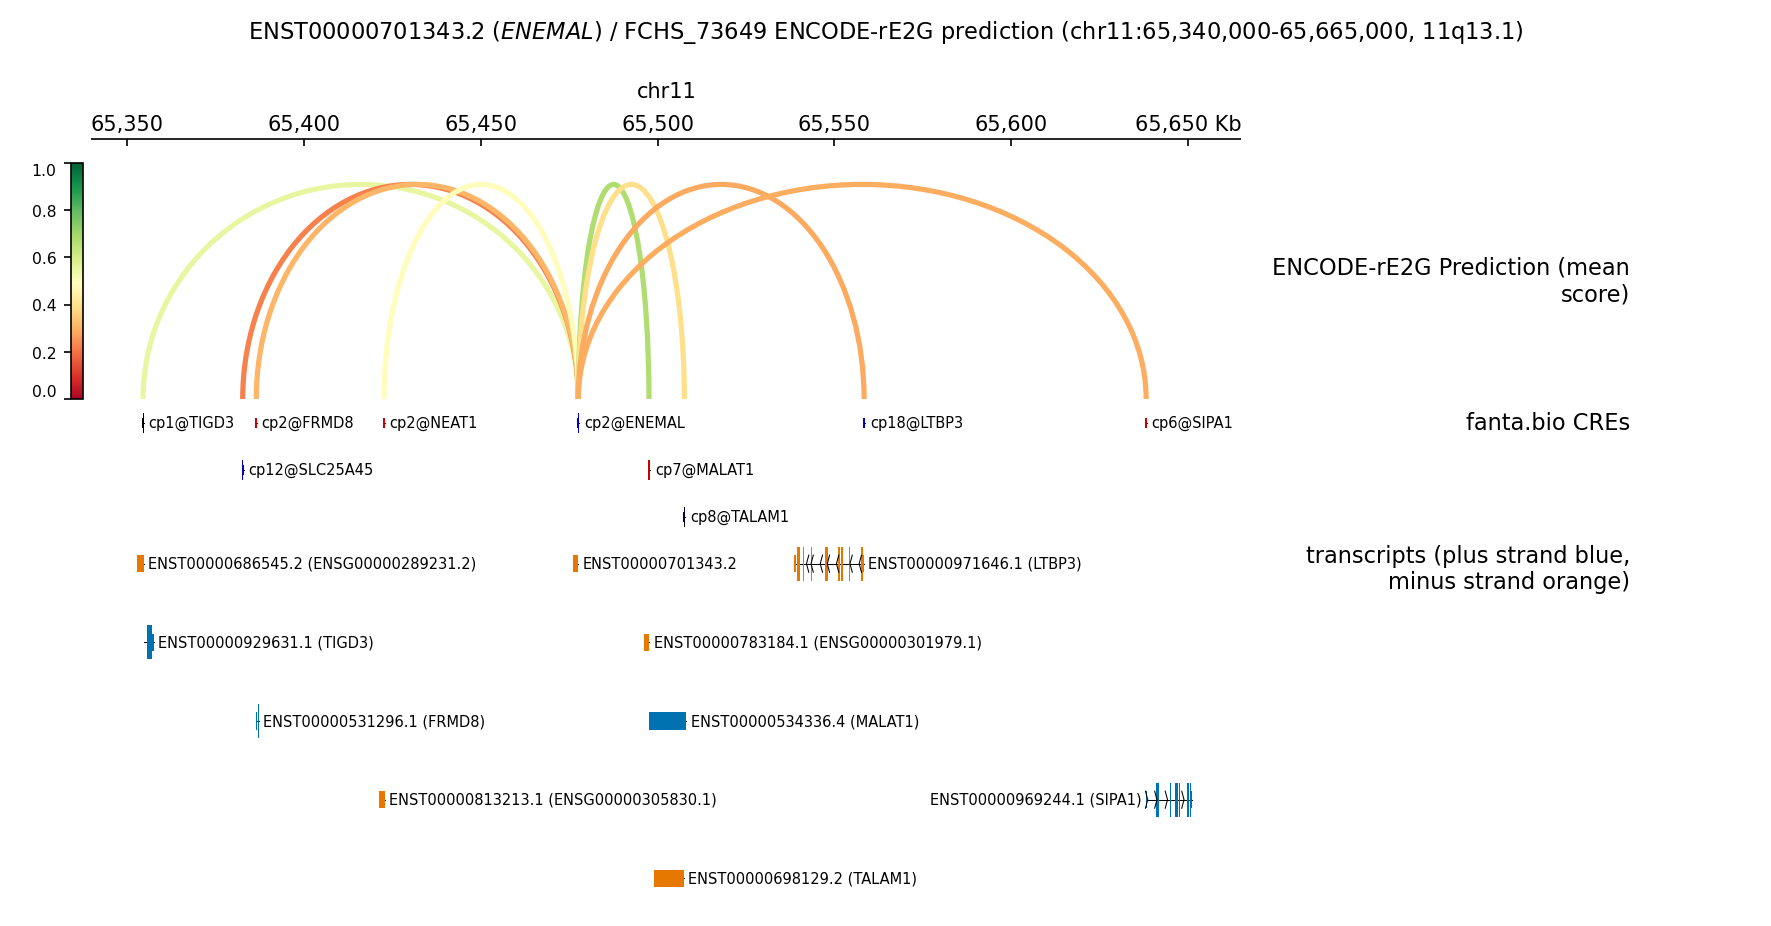

In [15]:
# Arcs on top, CRE anchors in the middle, transcript models at the bottom.
tracks_ini = out_dir / "ENST00000701343_FCHS_73649_tracks.ini"
figure_png = out_dir / "ENST00000701343_FCHS_73649_re2g.png"
tracks_ini.write_text(
    f"""\
[spacer]
height = 0.9

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[rE2G arcs]
file = {re2g_links.name}
title = ENCODE-rE2G Prediction (mean score)
file_type = links
links_type = arcs
use_middle = true
height = 4
color = RdYlGn
min_value = 0
max_value = 1
line_width = 2.5
line_style = solid
compact_arcs_level = 2

[spacer]
height = 0.2

[fanta CRE]
file = {cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 2.0
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[transcripts]
file = {tx_bed12.name}
title = transcripts (plus strand blue, minus strand orange)
file_type = bed
height = 6
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 7
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for gene symbols in the title to render fully italic.
mplrc = out_dir / "matplotlibrc"
mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(tracks_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.25",
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(figure_png),
        "--title",
        r"ENST00000701343.2 ($\mathrm{ENEMAL}$) / FCHS_73649 ENCODE-rE2G prediction (chr11:65,340,000-65,665,000, 11q13.1)",
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(mplrc)},
)
display(Image(filename=str(figure_png)))
